# 🧠 LSTM Hands-On Lab: Tasks for Students

**Goal:** after this lab you should be able to
1. explain what the gates of an LSTM do and why they fix the vanishing-gradient problem,
2. implement an LSTM cell from scratch,
3. count LSTM parameters by hand,
4. train LSTMs for time-series prediction, sequence memory, and text generation,
5. compare LSTM with a vanilla RNN / GRU and reason about the results.

**How this notebook works**
- Each section has a short **📘 Learn** part, followed by one or more **✏️ Task** cells.
- Fill in every place marked `# TODO`. Replace `...` / `None` with your own code.
- After most tasks there is a **✅ Check** cell. It should print `✔ passed`. Do not edit it.
- Answer written questions in the cells marked **Your answer:**.

| Section | Topic | Difficulty |
|---|---|---|
| 0 | Setup | – |
| 1 | Concept check | ⭐ |
| 2 | LSTM cell from scratch (NumPy) | ⭐⭐ |
| 3 | Counting parameters | ⭐⭐ |
| 4 | Sine-wave forecasting (PyTorch) | ⭐⭐ |
| 5 | Long-term memory: RNN vs LSTM | ⭐⭐⭐ |
| 6 | Character-level text generation | ⭐⭐⭐ |
| 7 | Free experiments + reflection | ⭐⭐ |

## 0. Setup

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.4.1+cpu | device: cpu


## 1. Concept check

### 📘 Learn
A vanilla RNN updates one hidden state: $h_t = \tanh(W x_t + U h_{t-1} + b)$.
During backpropagation through time the gradient is multiplied by (roughly) $U^\top \cdot \text{diag}(\tanh')$ **at every step**, so over many steps it **vanishes** (or explodes).

An **LSTM** adds a separate **cell state** $c_t$ (the "memory highway") and three **gates** (values between 0 and 1):

$$
\begin{aligned}
i_t &= \sigma(W_i x_t + U_i h_{t-1} + b_i) &&\text{input gate: how much new info to write}\\
f_t &= \sigma(W_f x_t + U_f h_{t-1} + b_f) &&\text{forget gate: how much old memory to keep}\\
g_t &= \tanh(W_g x_t + U_g h_{t-1} + b_g) &&\text{candidate memory}\\
o_t &= \sigma(W_o x_t + U_o h_{t-1} + b_o) &&\text{output gate: how much memory to expose}\\[4pt]
c_t &= f_t \odot c_{t-1} + i_t \odot g_t\\
h_t &= o_t \odot \tanh(c_t)
\end{aligned}
$$

The key line is $c_t = f_t \odot c_{t-1} + i_t \odot g_t$: it is **additive**, so the gradient $\partial c_t / \partial c_{t-1} = f_t$ can stay close to 1 and flow through many time steps.

### ✏️ Task 1: Answer in 1–3 sentences each
**Q1.** If $f_t = 1$ and $i_t = 0$ for all $t$, what happens to the cell state $c_t$?

**Q2.** If $f_t = 0$ for all $t$, what does the LSTM behave like?

**Q3.** Why is the forget-gate bias often initialised to a positive number (e.g. 1)?

**Q4.** What is the difference between the *hidden state* $h_t$ and the *cell state* $c_t$? Which one is passed to the next layer / the output layer?

**Your answers:**

**A1.** *(write here)*

**A2.** *(write here)*

**A3.** *(write here)*

**A4.** *(write here)*

## 2. LSTM cell from scratch (NumPy)

### 📘 Learn
In practice all four gates are computed with **one** big matrix multiplication and then split:

$$ z_t = W x_t + U h_{t-1} + b \in \mathbb{R}^{4H} $$

Then $z_t$ is cut into 4 chunks of size $H$. We use **PyTorch's order**: `i, f, g, o`.

Shapes (D = input size, H = hidden size):
- `x_t`: `(D,)`, `h_prev`, `c_prev`: `(H,)`
- `W`: `(4H, D)`, `U`: `(4H, H)`, `b`: `(4H,)`

### ✏️ Task 2a: Implement one LSTM step

In [2]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def lstm_cell_forward(x_t, h_prev, c_prev, W, U, b):
    '''One LSTM time step. Returns (h_t, c_t).'''
    H = h_prev.shape[0]

    # TODO 1: compute the pre-activations z (shape (4H,))
    z = W @ x_t + U @ h_prev + b

    # TODO 2: split z into 4 chunks (order: i, f, g, o) and apply the right activation to each
    i = sigmoid(z[0:H])        # sigmoid
    f = sigmoid(z[H:2 * H])    # sigmoid
    g = np.tanh(z[2 * H:3 * H])  # tanh
    o = sigmoid(z[3 * H:4 * H])  # sigmoid

    # TODO 3: new cell state and hidden state
    c_t = f * c_prev + i * g
    h_t = o * np.tanh(c_t)
    return h_t, c_t


### ✅ Check 2a: compare with PyTorch's `nn.LSTMCell`

In [3]:
D, H = 3, 4
torch_cell = nn.LSTMCell(D, H)
W = torch_cell.weight_ih.detach().numpy()                       # (4H, D)
U = torch_cell.weight_hh.detach().numpy()                       # (4H, H)
b = (torch_cell.bias_ih + torch_cell.bias_hh).detach().numpy()  # (4H,)

x  = np.random.randn(D).astype(np.float32)
h0 = np.random.randn(H).astype(np.float32)
c0 = np.random.randn(H).astype(np.float32)

h_mine, c_mine = lstm_cell_forward(x, h0, c0, W, U, b)
h_ref, c_ref = torch_cell(torch.tensor(x)[None], (torch.tensor(h0)[None], torch.tensor(c0)[None]))

assert np.allclose(h_mine, h_ref.detach().numpy()[0], atol=1e-5), "h_t is wrong"
assert np.allclose(c_mine, c_ref.detach().numpy()[0], atol=1e-5), "c_t is wrong"
print("✔ passed")

✔ passed


### ✏️ Task 2b: Run the cell over a whole sequence
Write `lstm_forward(X, W, U, b)` that loops over a sequence `X` of shape `(T, D)` starting from zero states and returns all hidden states `(T, H)` plus the final `c`.

In [4]:
def lstm_forward(X, W, U, b):
    T, D = X.shape
    H = U.shape[1]
    h = np.zeros(H, dtype=np.float32)
    c = np.zeros(H, dtype=np.float32)
    all_h = []
    # TODO: loop over time steps, call lstm_cell_forward, store each h
    for t in range(T):
        h, c = lstm_cell_forward(X[t], h, c, W, U, b)
        all_h.append(h)
    return np.stack(all_h), c


In [5]:
# ✅ Check 2b
X = np.random.randn(6, D).astype(np.float32)
H_mine, c_final = lstm_forward(X, W, U, b)

lstm = nn.LSTM(D, H, batch_first=True)
with torch.no_grad():
    lstm.weight_ih_l0.copy_(torch_cell.weight_ih); lstm.weight_hh_l0.copy_(torch_cell.weight_hh)
    lstm.bias_ih_l0.copy_(torch_cell.bias_ih);     lstm.bias_hh_l0.copy_(torch_cell.bias_hh)
    out, (hn, cn) = lstm(torch.tensor(X)[None])

assert H_mine.shape == (6, H)
assert np.allclose(H_mine, out[0].numpy(), atol=1e-5), "Hidden states differ from nn.LSTM"
assert np.allclose(c_final, cn[0, 0].numpy(), atol=1e-5), "Final cell state differs"
print("✔ passed")

✔ passed


### ✏️ Task 2c: Watch the gates (exploration)
Set the forget-gate bias very **high** (+10) and then very **low** (−10) and feed the same sequence. Plot $c_t$ over time for one hidden unit in both cases. *(Tip: the forget gate is the 2nd chunk of `b`, i.e. `b[H:2*H]`.)*

What do you observe? Write one sentence below the plot.

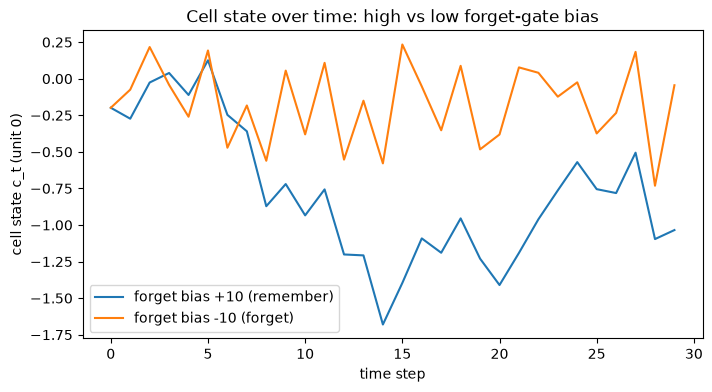

In [6]:
def run_and_collect_c(X, W, U, b):
    # TODO: copy your lstm_forward but also record c_t at every step; return array (T, H)
    T, D = X.shape
    H = U.shape[1]
    h = np.zeros(H, dtype=np.float32)
    c = np.zeros(H, dtype=np.float32)
    all_c = []
    for t in range(T):
        h, c = lstm_cell_forward(X[t], h, c, W, U, b)
        all_c.append(c.copy())
    return np.stack(all_c)

# TODO: build b_high / b_low from b, run, and plot unit 0 of c_t for both
X_seq = np.random.randn(30, D).astype(np.float32)   # same 30-step sequence for both runs
b_high = b.copy(); b_high[H:2 * H] = 10.0   # forget gate wide open -> memory is kept
b_low = b.copy(); b_low[H:2 * H] = -10.0    # forget gate shut -> memory is erased
c_high = run_and_collect_c(X_seq, W, U, b_high)
c_low = run_and_collect_c(X_seq, W, U, b_low)

plt.figure(figsize=(8, 4))
plt.plot(c_high[:, 0], label="forget bias +10 (remember)")
plt.plot(c_low[:, 0], label="forget bias -10 (forget)")
plt.xlabel("time step")
plt.ylabel("cell state c_t (unit 0)")
plt.title("Cell state over time: high vs low forget-gate bias")
plt.legend()
plt.show()


**Observation:** *(write here)*

## 3. Counting parameters

### 📘 Learn
For one LSTM layer with input size $D$ and hidden size $H$:

- 4 gates, each with an input matrix $(H \times D)$, a recurrent matrix $(H \times H)$ and a bias $(H)$.
- PyTorch uses **two** bias vectors per gate (`bias_ih` and `bias_hh`), so the total biases are $8H$.

For layers after the first, the input size is $H$ (or $2H$ if bidirectional).

### ✏️ Task 3: Write `count_lstm_params(D, H, num_layers=1, bidirectional=False)`

In [7]:
def count_lstm_params(D, H, num_layers=1, bidirectional=False):
    # TODO: return the total number of trainable parameters of nn.LSTM(D, H, num_layers, bidirectional=...)
    # One LSTM layer = 4 gates x (input matrix H x in_size + recurrent matrix H x H + 2 bias vectors of size H).
    # First layer input size is D; later layers take H inputs (2H if bidirectional).
    n_dir = 2 if bidirectional else 1
    total = 0
    in_size = D
    for _ in range(num_layers):
        total += n_dir * 4 * (H * in_size + H * H + 2 * H)
        in_size = H * n_dir
    return total


In [8]:
# ✅ Check 3
for (D, H, L, bi) in [(1, 8, 1, False), (10, 32, 1, False), (10, 32, 2, False), (5, 16, 3, True)]:
    m = nn.LSTM(D, H, num_layers=L, bidirectional=bi)
    real = sum(p.numel() for p in m.parameters())
    mine = count_lstm_params(D, H, L, bi)
    assert real == mine, f"D={D}, H={H}, L={L}, bi={bi}: expected {real}, got {mine}"
print("✔ passed")

✔ passed


**Thinking question:** an LSTM has ~4× the parameters of a vanilla RNN with the same sizes, and a GRU has ~3×. Verify this quickly with `nn.RNN`, `nn.GRU`, `nn.LSTM` for `D=10, H=32` and write the three numbers below.

In [9]:
# TODO: print parameter counts for nn.RNN, nn.GRU, nn.LSTM with D=10, H=32
for name, cls in [("RNN", nn.RNN), ("GRU", nn.GRU), ("LSTM", nn.LSTM)]:
    m = cls(10, 32)
    n = sum(p.numel() for p in m.parameters())
    print(f"{name}: {n} parameters")
# RNN has 1 set of weights, GRU 3 (reset/update/new), LSTM 4 (i/f/g/o) -> roughly 1x / 3x / 4x.


RNN: 1408 parameters
GRU: 4224 parameters
LSTM: 5632 parameters


## 4. Sine-wave forecasting with PyTorch

### 📘 Learn
Typical PyTorch LSTM recipe (`batch_first=True`):

| Tensor | Shape |
|---|---|
| input to `nn.LSTM` | `(batch, seq_len, input_size)` |
| `output` | `(batch, seq_len, hidden_size)`, the hidden state at **every** step |
| `h_n`, `c_n` | `(num_layers, batch, hidden_size)`, the **final** states |

For **many-to-one** prediction (predict the next value) we take the last time step: `output[:, -1, :]`, and pass it to a `nn.Linear`.

### ✏️ Task 4a: Build the dataset
We have a noisy sine wave. Use a sliding window: the input is `window` consecutive values, the target is the **next** value.

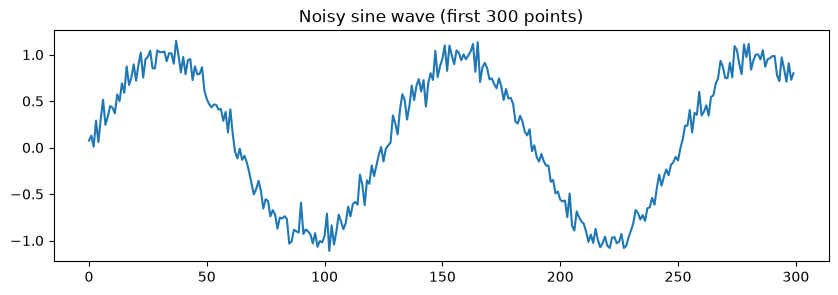

torch.Size([1576, 30, 1]) torch.Size([1576, 1]) torch.Size([394, 30, 1])


In [10]:
t = np.linspace(0, 100, 2000)
series = np.sin(t) + 0.1 * np.random.randn(len(t))
series = series.astype(np.float32)

plt.figure(figsize=(10, 3)); plt.plot(series[:300]); plt.title("Noisy sine wave (first 300 points)"); plt.show()

def make_windows(series, window):
    '''Return X of shape (N, window, 1) and y of shape (N, 1).'''
    X, y = [], []
    # TODO: fill X and y with sliding windows
    for i in range(len(series) - window):
        X.append(series[i:i + window])   # window consecutive values
        y.append(series[i + window])     # the next value after the window
    X = np.array(X, dtype=np.float32)[..., None]
    y = np.array(y, dtype=np.float32)[:, None]
    return X, y

WINDOW = 30
X, y = make_windows(series, WINDOW)

# chronological split (never shuffle time series before splitting!)
split = int(0.8 * len(X))
X_train, y_train = torch.tensor(X[:split]), torch.tensor(y[:split])
X_test,  y_test  = torch.tensor(X[split:]), torch.tensor(y[split:])
print(X_train.shape, y_train.shape, X_test.shape)


In [11]:
# ✅ Check 4a
assert X.shape == (len(series) - WINDOW, WINDOW, 1), "wrong number of windows"
assert np.isclose(X[0, 0, 0], series[0]) and np.isclose(y[0, 0], series[WINDOW]), "window/target misaligned"
print("✔ passed")

✔ passed


### ✏️ Task 4b: Define the model

In [12]:
class SineLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        super().__init__()
        # TODO: define self.lstm (batch_first=True) and self.fc (hidden_size -> 1)
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # TODO: run the LSTM, take the LAST time step of the output, pass through fc
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


In [13]:
# ✅ Check 4b
m = SineLSTM()
assert m(torch.randn(5, WINDOW, 1)).shape == (5, 1), "output should be (batch, 1)"
print("✔ passed")

✔ passed


### ✏️ Task 4c: Train it
Use `MSELoss` and `Adam` (lr=0.01), mini-batches of 64, around 15 epochs. Record the train and test loss each epoch.

In [14]:
def train_regressor(model, X_train, y_train, X_test, y_test, epochs=15, lr=1e-2, batch_size=64):
    model.to(device)
    criterion = nn.MSELoss()  # TODO
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # TODO
    train_hist, test_hist = [], []

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X_train))
        total = 0.0
        for k in range(0, len(X_train), batch_size):
            idx = perm[k:k + batch_size]
            xb, yb = X_train[idx].to(device), y_train[idx].to(device)
            # TODO: forward, loss, zero_grad, backward, (gradient clipping, see below), step
            pred = model(xb)
            loss = criterion(pred, yb)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total += loss.item() * len(idx)

        model.eval()
        with torch.no_grad():
            test_loss = criterion(model(X_test.to(device)), y_test.to(device)).item()
        train_hist.append(total / len(X_train)); test_hist.append(test_loss)
        print(f"epoch {epoch+1:2d} | train {train_hist[-1]:.4f} | test {test_loss:.4f}")
    return train_hist, test_hist

torch.manual_seed(SEED)
model = SineLSTM(hidden_size=32)
train_hist, test_hist = train_regressor(model, X_train, y_train, X_test, y_test)


epoch  1 | train 0.1244 | test 0.0278


epoch  2 | train 0.0184 | test 0.0149


epoch  3 | train 0.0148 | test 0.0141
epoch  4 | train 0.0147 | test 0.0140
epoch  5 | train 0.0144 | test 0.0140


epoch  6 | train 0.0145 | test 0.0142
epoch  7 | train 0.0142 | test 0.0146


epoch  8 | train 0.0133 | test 0.0133
epoch  9 | train 0.0135 | test 0.0123


epoch 10 | train 0.0129 | test 0.0127
epoch 11 | train 0.0134 | test 0.0125


epoch 12 | train 0.0124 | test 0.0122
epoch 13 | train 0.0129 | test 0.0134


epoch 14 | train 0.0135 | test 0.0130
epoch 15 | train 0.0131 | test 0.0118


> 💡 **Gradient clipping.** LSTMs fix *vanishing* gradients but can still have *exploding* ones. Add
> `torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)` between `backward()` and `step()`.

In [15]:
# ✅ Check 4c
assert test_hist[-1] < 0.05, f"Test MSE is {test_hist[-1]:.3f}, expected < 0.05 (noise variance is 0.01). Check your loop."
print("✔ passed")

✔ passed


### ✏️ Task 4d: Visualise predictions and do a multi-step forecast

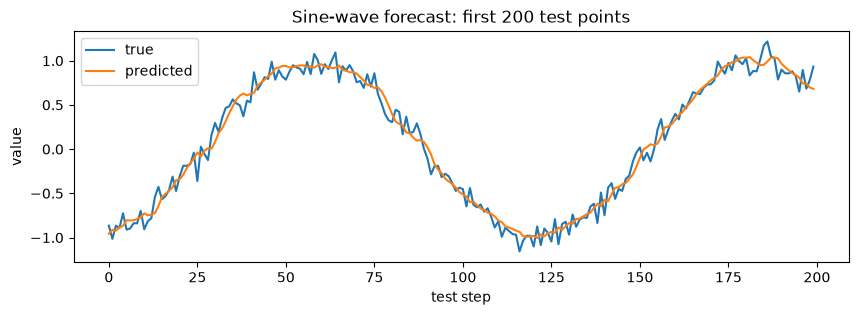

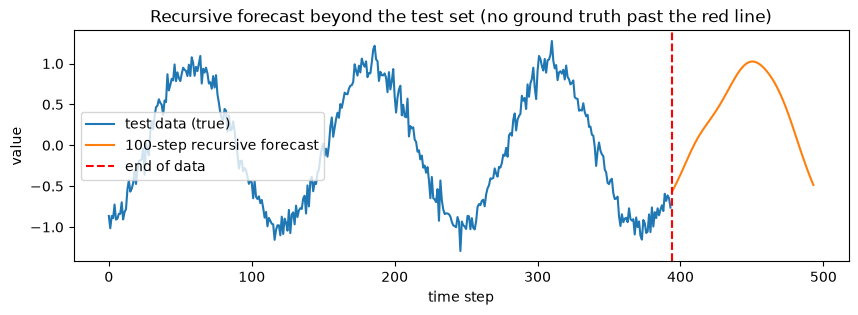

In [16]:
model.eval()
with torch.no_grad():
    pred = model(X_test.to(device)).cpu().numpy()

# TODO 1: plot y_test and pred together for the first 200 test points
plt.figure(figsize=(10, 3))
plt.plot(y_test[:200].numpy(), label="true")
plt.plot(pred[:200], label="predicted")
plt.xlabel("test step")
plt.ylabel("value")
plt.title("Sine-wave forecast: first 200 test points")
plt.legend()
plt.show()

# TODO 2: recursive forecasting. Start from the last window of the TEST set, predict one step,
#         append the prediction to the window, drop the oldest value, repeat for 100 steps.
def forecast(model, last_window, steps=100):
    '''last_window: tensor (WINDOW, 1). Returns a list of `steps` predicted floats.'''
    model.eval()
    window = last_window.clone().to(device)   # shape (WINDOW, 1)
    preds = []
    with torch.no_grad():
        for _ in range(steps):
            nxt = model(window.unsqueeze(0)).item()   # predict one step ahead
            preds.append(nxt)
            window = torch.cat([window[1:], torch.tensor([[nxt]], device=device)], dim=0)
    return preds

# TODO 3: plot the 100-step forecast next to the true continuation of the curve
future = forecast(model, X_test[-1])
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(y_test)), y_test.numpy(), label="test data (true)")
plt.plot(np.arange(len(y_test), len(y_test) + 100), future, label="100-step recursive forecast")
plt.axvline(len(y_test), color="red", linestyle="--", label="end of data")
plt.xlabel("time step")
plt.ylabel("value")
plt.title("Recursive forecast beyond the test set (no ground truth past the red line)")
plt.legend()
plt.show()


**Question:** does the recursive forecast stay accurate for all 100 steps? Why do errors usually accumulate?

**Your answer:** *(write here)*

## 5. Long-term memory: RNN vs LSTM

### 📘 Learn
We build a task where the answer depends on the **very first** element of a long sequence:

- Input: a sequence of `T` random digits (0–9), one-hot encoded.
- Target: the **first** digit.

To solve this the network must carry information across `T-1` steps of useless noise. A vanilla RNN struggles as `T` grows; the LSTM should keep working.

In [17]:
def make_memory_data(n, T, n_classes=10):
    digits = torch.randint(0, n_classes, (n, T))
    X = torch.nn.functional.one_hot(digits, n_classes).float()   # (n, T, 10)
    y = digits[:, 0]                                             # (n,)
    return X, y

Xm, ym = make_memory_data(4, 6)
print(Xm.shape, ym)

torch.Size([4, 6, 10]) tensor([7, 9, 6, 0])


### ✏️ Task 5a: A model that can be either an RNN or an LSTM
Write `MemoryNet(rnn_type, ...)` where `rnn_type ∈ {"rnn", "lstm", "gru"}`. It reads the sequence and classifies using the final time step.

In [18]:
class MemoryNet(nn.Module):
    def __init__(self, rnn_type="lstm", input_size=10, hidden_size=64, n_classes=10):
        super().__init__()
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[rnn_type]
        # TODO: self.rnn = ..., self.fc = ...
        self.rnn = rnn_cls(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, n_classes)
        # Start the "keep" gate bias at +2 so the gates begin mostly OPEN (the model
        # starts out remembering). With the default ~0 bias the LSTM/GRU forget most
        # of the first digit before any learning signal reaches it (see Q3 in Section 1).
        if rnn_type == "lstm":
            # LSTM biases are (4H,) in order i, f, g, o -> the forget gate is chunk 1
            with torch.no_grad():
                self.rnn.bias_ih_l0[hidden_size:2 * hidden_size].fill_(2.0)
                self.rnn.bias_hh_l0[hidden_size:2 * hidden_size].fill_(2.0)
        elif rnn_type == "gru":
            # GRU biases are (3H,) in order r, z, n -> the update ("keep") gate is chunk 1
            with torch.no_grad():
                self.rnn.bias_ih_l0[hidden_size:2 * hidden_size].fill_(2.0)
                self.rnn.bias_hh_l0[hidden_size:2 * hidden_size].fill_(2.0)

    def forward(self, x):
        # TODO: return logits (batch, n_classes) computed from the last time step
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


In [19]:
# ✅ Check 5a
for kind in ["rnn", "lstm", "gru"]:
    assert MemoryNet(kind)(torch.randn(3, 7, 10)).shape == (3, 10), f"{kind}: wrong output shape"
print("✔ passed")

✔ passed


### ✏️ Task 5b: Train and compare
Complete `train_memory` (cross-entropy, Adam lr=3e-3, gradient clipping 1.0). Fresh random data is generated every step, so there is no overfitting.

In [20]:
def train_memory(rnn_type, T, steps=600, batch_size=64, lr=3e-3, hidden=64):
    torch.manual_seed(SEED)
    model = MemoryNet(rnn_type, hidden_size=hidden).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for step in range(steps):
        Xb, yb = make_memory_data(batch_size, T)
        Xb, yb = Xb.to(device), yb.to(device)
        # TODO: one optimisation step (forward, loss, backward, clip, step)
        logits = model(Xb)
        loss = criterion(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

    # final accuracy on fresh data
    model.eval()
    with torch.no_grad():
        Xt, yt = make_memory_data(2000, T)
        acc = (model(Xt.to(device)).argmax(1).cpu() == yt).float().mean().item()
    return acc

# chance level is 0.10
results = {}
for kind in ["rnn", "lstm", "gru"]:
    for T in [5, 20, 50]:
        results[(kind, T)] = train_memory(kind, T)
        print(f"{kind:>4} | T={T:3d} | accuracy = {results[(kind, T)]:.2f}")


 rnn | T=  5 | accuracy = 1.00


 rnn | T= 20 | accuracy = 1.00


 rnn | T= 50 | accuracy = 0.10


lstm | T=  5 | accuracy = 1.00


lstm | T= 20 | accuracy = 0.99


lstm | T= 50 | accuracy = 0.99


 gru | T=  5 | accuracy = 1.00


 gru | T= 20 | accuracy = 1.00


 gru | T= 50 | accuracy = 1.00


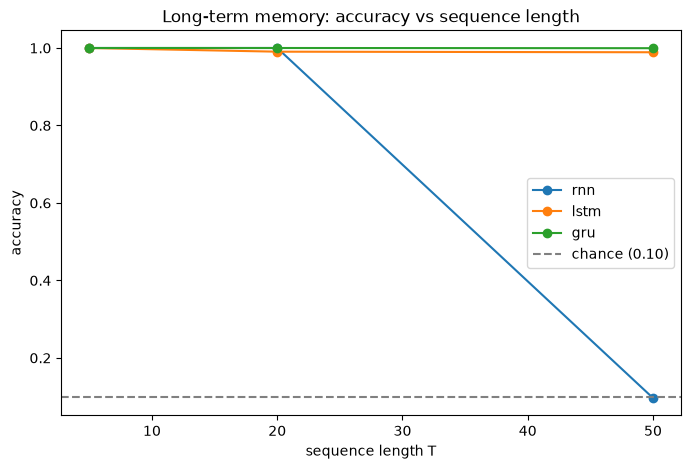

In [21]:
# TODO: plot accuracy (y-axis) vs. sequence length T (x-axis), one line per model type
plt.figure(figsize=(8, 5))
for kind in ["rnn", "lstm", "gru"]:
    Ts = [5, 20, 50]
    accs = [results[(kind, T)] for T in Ts]
    plt.plot(Ts, accs, marker="o", label=kind)
plt.axhline(0.10, color="gray", linestyle="--", label="chance (0.10)")
plt.xlabel("sequence length T")
plt.ylabel("accuracy")
plt.title("Long-term memory: accuracy vs sequence length")
plt.legend()
plt.show()


**Questions**
1. At which `T` does the vanilla RNN start to fail? Does the LSTM fail too if you push `T` to 100 or 200? (try it, you may need more `steps`)
2. Which of the 3 models trains fastest for small `T`? Why might that be?

**Your answers:** *(write here)*

### ✏️ Task 5c (challenge): Measure the vanishing gradient directly
Take a trained-or-untrained `MemoryNet` and a batch with `T = 50`. Make the input require gradients, compute the loss, call `backward()`, and compute for each time step $t$ the norm $\|\partial L / \partial x_t\|$. Plot it on a **log** y-axis for `rnn` and `lstm`.

You should see that for the RNN the gradient at early time steps is much smaller than at late ones.

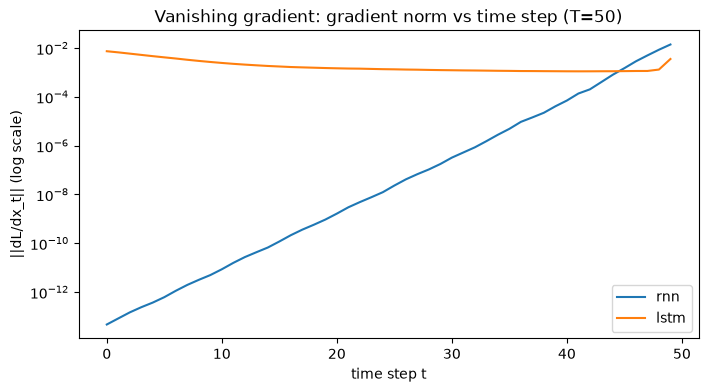

In [22]:
def grad_norm_per_timestep(rnn_type, T=50, batch_size=64):
    torch.manual_seed(SEED)
    model = MemoryNet(rnn_type).to(device)
    Xb, yb = make_memory_data(batch_size, T)
    Xb = Xb.to(device).detach().requires_grad_(True)   # leaf tensor so .grad is filled in
    yb = yb.to(device)
    # TODO: loss = cross-entropy, backward, then return a numpy array of length T
    #       with the gradient norm of Xb for each time step (norm over batch and features)
    logits = model(Xb)
    loss = nn.CrossEntropyLoss()(logits, yb)
    loss.backward()
    grads = Xb.grad.detach().cpu().numpy()   # shape (batch, T, features)
    return np.linalg.norm(grads, axis=(0, 2))  # one norm per time step

# TODO: plot for "rnn" and "lstm" on a log scale
plt.figure(figsize=(8, 4))
for kind in ["rnn", "lstm"]:
    norms = grad_norm_per_timestep(kind)
    plt.plot(np.arange(len(norms)), norms, label=kind)
plt.yscale("log")
plt.xlabel("time step t")
plt.ylabel("||dL/dx_t|| (log scale)")
plt.title("Vanishing gradient: gradient norm vs time step (T=50)")
plt.legend()
plt.show()


**What do you see?** *(write here)*

## 6. Character-level text generation

### 📘 Learn
A **language model** predicts the next character from the previous ones. Once trained we can **generate** text: feed a seed, sample the next character from the output distribution, append it, repeat.

**Temperature** $\tau$ controls randomness: sample from $\text{softmax}(\text{logits}/\tau)$.
- $\tau \to 0$: always the most likely character (repetitive)
- $\tau = 1$: the model's true distribution
- $\tau > 1$: more random / creative (and more errors)

Here we use a tiny text. For better results later, replace it with a larger text file (e.g. a book from Project Gutenberg, or your own writing).

In [23]:
text = (
    "the quick brown fox jumps over the lazy dog. "
    "a long short term memory network keeps information for a long time. "
    "the forget gate decides what to throw away and the input gate decides what to store. "
    "the cell state carries information through time and the output gate decides what to show. "
    "recurrent networks read one token at a time and remember the past. "
) * 20
print(len(text), "characters")

7100 characters


### ✏️ Task 6a: Vocabulary and dataset

In [24]:
# TODO 1: build `chars` (sorted list of unique characters), `stoi` (char -> int), `itos` (int -> char)
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
vocab_size = len(chars)

SEQ_LEN = 40

# TODO 2: build X_txt (N, SEQ_LEN) of integer ids and Y_txt (N, SEQ_LEN) where
#         Y_txt[i] is X_txt[i] shifted ONE character to the right (next-char targets at every position)
ids = [stoi[c] for c in text]
X_txt = torch.tensor([ids[i:i + SEQ_LEN] for i in range(len(ids) - SEQ_LEN)], dtype=torch.long)
Y_txt = torch.tensor([ids[i + 1:i + SEQ_LEN + 1] for i in range(len(ids) - SEQ_LEN)], dtype=torch.long)
print(vocab_size, X_txt.shape, Y_txt.shape)


28 torch.Size([7060, 40]) torch.Size([7060, 40])


In [25]:
# ✅ Check 6a
assert all(itos[stoi[c]] == c for c in chars)
assert X_txt.shape == Y_txt.shape and X_txt.shape[1] == SEQ_LEN
assert (X_txt[0, 1:] == Y_txt[0, :-1]).all(), "targets must be inputs shifted by one"
print("✔ passed")

✔ passed


### ✏️ Task 6b: Model
Architecture: `Embedding → LSTM (2 layers, dropout 0.2) → Linear(vocab)`.
This time the LSTM outputs are used at **every** time step (many-to-many), so the logits should have shape `(batch, seq_len, vocab)`.

In [26]:
class CharLSTM(nn.Module):
    def __init__(self, vocab_size, emb=32, hidden=128, layers=2, dropout=0.2):
        super().__init__()
        # TODO: self.emb, self.lstm, self.fc
        self.emb = nn.Embedding(vocab_size, emb)
        self.lstm = nn.LSTM(emb, hidden, num_layers=layers, dropout=dropout, batch_first=True)
        self.fc = nn.Linear(hidden, vocab_size)

    def forward(self, x, state=None):
        # TODO: embed -> lstm (pass `state`) -> fc; return logits AND the new state
        e = self.emb(x)
        out, state = self.lstm(e, state)
        logits = self.fc(out)
        return logits, state


In [27]:
# ✅ Check 6b
m = CharLSTM(vocab_size)
logits, st = m(torch.randint(0, vocab_size, (4, SEQ_LEN)))
assert logits.shape == (4, SEQ_LEN, vocab_size)
print("✔ passed")

✔ passed


### ✏️ Task 6c: Train
Flatten logits to `(batch*seq, vocab)` and targets to `(batch*seq,)` for `CrossEntropyLoss`. Aim for a loss below ~0.5 on this tiny text.

In [28]:
def train_char_model(model, X, Y, epochs=8, lr=3e-3, batch_size=64):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        perm = torch.randperm(len(X)); total = 0.0
        for k in range(0, len(X), batch_size):
            idx = perm[k:k + batch_size]
            xb, yb = X[idx].to(device), Y[idx].to(device)
            # TODO: forward, reshape, loss, backward, clip, step
            logits, _ = model(xb)
            loss = criterion(logits.reshape(-1, logits.shape[-1]), yb.reshape(-1))
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total += loss.item() * len(idx)
        print(f"epoch {epoch+1} | loss {total/len(X):.4f}")

torch.manual_seed(SEED)
char_model = CharLSTM(vocab_size)
train_char_model(char_model, X_txt, Y_txt)


epoch 1 | loss 1.5506


epoch 2 | loss 0.1643


epoch 3 | loss 0.1095


epoch 4 | loss 0.0978


epoch 5 | loss 0.0927


epoch 6 | loss 0.0885


epoch 7 | loss 0.0865


epoch 8 | loss 0.0851


### ✏️ Task 6d: Generate text with temperature

In [29]:
@torch.no_grad()
def generate(model, seed, length=200, temperature=1.0):
    model.eval()
    out = list(seed)
    # TODO 1: feed the whole seed through the model to warm up `state`
    seed_ids = torch.tensor([[stoi[c] for c in seed]], device=device)
    _, state = model(seed_ids)
    # TODO 2: loop `length` times: take logits of the LAST position, divide by temperature,
    #         softmax, sample with torch.multinomial, append char, feed ONLY the new char with the carried state
    last_id = seed_ids[0, -1].view(1, 1)
    for _ in range(length):
        logits, state = model(last_id, state)
        probs = torch.softmax(logits[0, -1] / temperature, dim=-1)
        nxt = torch.multinomial(probs, num_samples=1)
        out.append(itos[int(nxt.item())])
        last_id = nxt.view(1, 1)
    return "".join(out)

for tau in [0.3, 0.8, 1.5]:
    print(f"--- temperature {tau} ---")
    print(generate(char_model, "the forget gate ", 200, tau), "\n")


--- temperature 0.3 ---


the forget gate decides what to throw away and the input gate decides what to store. the cell state carries information through time and the output gate decides what to store. the cell state carries information throu 

--- temperature 0.8 ---
the forget gate networes what to store. the cell state carries information through time and the output gate decides what to show. recurrent networks read one token at a time and remember the past. the quick brown fox 

--- temperature 1.5 ---


the forget gate decides what to throw away and the input ghet gate decides what to store. the cell state carries information through time and the output gate decides what to show. recurrent networks read one token at 



**Questions**
1. How does the text change with temperature?
2. Why do we pass `state` between calls instead of re-feeding the full history each time? Is the result identical?

**Your answers:** *(write here)*

## 7. Free experiments & reflection

### ✏️ Task 7a: Ablation on the sine task (Section 4)
Pick **at least three** of the experiments below, run them, and fill in the table with the final test MSE.

| Experiment | Change | Final test MSE | Notes |
|---|---|---|---|
| Baseline | `hidden=32`, 1 layer | | |
| Bigger hidden | `hidden=128` | | |
| Deeper | `num_layers=2` | | |
| Shorter window | `WINDOW=5` | | |
| Longer window | `WINDOW=100` | | |
| Replace `nn.LSTM` by `nn.GRU` | | | |
| Replace `nn.LSTM` by `nn.RNN` | | | |
| No gradient clipping | | | |

In [30]:
# Your experiment code here
# Ablation on the sine task: 3 quick experiments (8 epochs each, same recipe as Section 4).
# The baseline (hidden=32, 1 layer, WINDOW=30, 15 epochs) was already trained in Section 4c.
print(f"Baseline (hidden=32, 1 layer, WINDOW=30): final test MSE = {test_hist[-1]:.4f}")

# Experiment 1: bigger hidden size
torch.manual_seed(SEED)
m_big = SineLSTM(hidden_size=128)
_, test_big = train_regressor(m_big, X_train, y_train, X_test, y_test, epochs=8)
print(f"Bigger hidden (hidden=128): final test MSE = {test_big[-1]:.4f}")

# Experiment 2: deeper (2 layers)
torch.manual_seed(SEED)
m_deep = SineLSTM(hidden_size=32, num_layers=2)
_, test_deep = train_regressor(m_deep, X_train, y_train, X_test, y_test, epochs=8)
print(f"Deeper (num_layers=2): final test MSE = {test_deep[-1]:.4f}")

# Experiment 3: shorter window (WINDOW=5) -> rebuild the dataset first
X5, y5 = make_windows(series, 5)
split5 = int(0.8 * len(X5))
X5_train, y5_train = torch.tensor(X5[:split5]), torch.tensor(y5[:split5])
X5_test, y5_test = torch.tensor(X5[split5:]), torch.tensor(y5[split5:])
torch.manual_seed(SEED)
m_short = SineLSTM(hidden_size=32)
_, test_short = train_regressor(m_short, X5_train, y5_train, X5_test, y5_test, epochs=8)
print(f"Shorter window (WINDOW=5): final test MSE = {test_short[-1]:.4f}")


Baseline (hidden=32, 1 layer, WINDOW=30): final test MSE = 0.0118


epoch  1 | train 0.2310 | test 0.0230


epoch  2 | train 0.0177 | test 0.0149


epoch  3 | train 0.0161 | test 0.0147


epoch  4 | train 0.0150 | test 0.0139


...

epoch  6 | train 0.0152 | test 0.0138


epoch  7 | train 0.0155 | test 0.0138
epoch  8 | train 0.0156 | test 0.0179
Deeper (num_layers=2): final test MSE = 0.0179


epoch  1 | train 0.1285 | test 0.0241
epoch  2 | train 0.0254 | test 0.0230
epoch  3 | train 0.0213 | test 0.0195


epoch  4 | train 0.0190 | test 0.0179
epoch  5 | train 0.0180 | test 0.0169
epoch  6 | train 0.0180 | test 0.0175


epoch  7 | train 0.0185 | test 0.0187
epoch  8 | train 0.0179 | test 0.0167
Shorter window (WINDOW=5): final test MSE = 0.0167


### ✏️ Task 7b: Bidirectional LSTM
Set `bidirectional=True` in one of your models. What happens to (i) the output feature size of the LSTM, (ii) the number of parameters? Does a bidirectional LSTM make sense for *forecasting the future*? For *classifying a sentence*? Explain.

**Your answer:** *(write here)*

### ✏️ Task 7c: Final reflection (4–6 sentences)
In your own words: **why does an LSTM remember better than a vanilla RNN?** Mention the cell state, the forget gate and the gradient flow. Then name one task where you would prefer a GRU or a Transformer over an LSTM and say why.

**Your answer:** *(write here)*

---
🎉 **Done!** Before submitting: *Kernel → Restart & Run All* and make sure every ✅ Check prints `✔ passed`.